# EDA — Churn Prediction Rental

Eksplorasi data dari hasil `Preprocessing.ipynb` (folder `data/processed/`), sebelum masuk
ke tahap permodelan. Tujuan: cari fitur yang benar-benar membedakan customer churn vs active,
validasi kualitas data hasil preprocessing, dan konfirmasi keputusan (leakage, threshold,
train/test split) secara visual.

**Urutan notebook:**
1. Load semua file processed
2. EDA `customer_churn_features.csv` — target, distribusi fitur, bivariate vs churn, korelasi
3. EDA `orders_churn_detailed.csv` — tren order, seasonality, overdue
4. EDA `draft_quotations_segment.csv` — segmen lead/orphan
5. Sanity check train vs test split
6. Ringkasan insight & rekomendasi fitur untuk modeling


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titleweight'] = 'bold'

try:
    BASE_DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    BASE_DIR = os.getcwd()

PROJECT_ROOT = BASE_DIR

PROCESSED_DIR = os.path.join(
    PROJECT_ROOT,
    'data',
    'processed'
)

print("BASE_DIR     :", BASE_DIR)
print("PROJECT_ROOT :", PROJECT_ROOT)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("Files        :", os.listdir(PROCESSED_DIR))

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 150)


BASE_DIR     : d:\Project Syafiq\Churn_Prediction_Rental_Update\data_preprocessing
PROJECT_ROOT : d:\Project Syafiq\Churn_Prediction_Rental_Update\data_preprocessing
PROCESSED_DIR: d:\Project Syafiq\Churn_Prediction_Rental_Update\data_preprocessing\data\processed
Files        : ['crm_opportunity_clean.csv', 'customer_churn_features.csv', 'customer_crm_info.csv', 'customer_risk_scores.csv', 'draft_quotations_segment.csv', 'feature_selection_recommendation.csv', 'orders_churn_detailed.csv', 'scaler.pkl', 'test_scaled.csv', 'test_unscaled.csv', 'train_scaled.csv', 'train_unscaled.csv']


## 1. Load Semua File Processed

In [2]:
cf = pd.read_csv(
    os.path.join(PROCESSED_DIR, 'customer_churn_features.csv')
)

orders = pd.read_csv(
    os.path.join(PROCESSED_DIR, 'orders_churn_detailed.csv'),
    parse_dates=['Order Date', 'Start Date', 'End Date']
)

draft = pd.read_csv(
    os.path.join(PROCESSED_DIR, 'draft_quotations_segment.csv'),
    parse_dates=['latest_draft_date']
)

feat_sel = pd.read_csv(
    os.path.join(PROCESSED_DIR, 'feature_selection_recommendation.csv')
)

train_unscaled = pd.read_csv(
    os.path.join(PROCESSED_DIR, 'train_unscaled.csv')
)

test_unscaled = pd.read_csv(
    os.path.join(PROCESSED_DIR, 'test_unscaled.csv')
)

train_scaled = pd.read_csv(
    os.path.join(PROCESSED_DIR, 'train_scaled.csv')
)

test_scaled = pd.read_csv(
    os.path.join(PROCESSED_DIR, 'test_scaled.csv')
)

print(f"customer_churn_features : {cf.shape}")
print(f"orders_churn_detailed   : {orders.shape}")
print(f"draft_quotations_segment: {draft.shape}")
print(f"feature_selection_report: {feat_sel.shape}")
print(f"train/test unscaled     : {train_unscaled.shape} / {test_unscaled.shape}")
print(f"train/test scaled       : {train_scaled.shape} / {test_scaled.shape}")

cf.head()

customer_churn_features : (635, 67)
orders_churn_detailed   : (2328, 20)
draft_quotations_segment: (14, 6)
feature_selection_report: (42, 3)
train/test unscaled     : (508, 51) / (127, 51)
train/test scaled       : (508, 51) / (127, 51)


,Customer,total_orders,first_order_date,last_order_date,unique_order_dates,total_invoiced,avg_invoiced,invoiced_count,total_paid,avg_paid,total_project_value,avg_project_value,avg_lifetime_days,pct_overdue_rentals,last_end_date,n_running_orders,churn_flag,churn_label,order_span_days,order_frequency_per_month,avg_gap_between_orders_days,payment_ratio,has_payment_data,payment_ratio_imputed,outstanding_balance,confirmation_rate,days_to_contract_end,has_project_value,is_one_time_customer,pct_komputer_laptop,pct_lainnya,pct_mobil,pct_motor,pct_televisi,first_order_month,first_order_quarter,first_order_year,customer_age_months,acquisition_year_volume,pct_sms_closed_rental,pct_sms_confirmed_rental,pct_sms_expired_rent_on_going,pct_sms_expired_rent_returned_done,pct_sms_expired_rent_returned_partial,pct_sms_on_going_delivered,pct_sms_on_going_partial_delivery,pct_sms_unknown,pct_problematic_rental_state,pct_status_closed_rental,pct_status_confirmed_rental,dominant_product_category_Komputer/Laptop,dominant_product_category_Lainnya,dominant_product_category_Mobil,dominant_product_category_Motor,dominant_product_category_Televisi,order_frequency_category_frequent,order_frequency_category_occasional,order_frequency_category_one_time,order_frequency_category_rare,order_frequency_category_regular,"order_span_quartile_(-0.001, 470.5]","order_span_quartile_(470.5, 1785.0]",purchase_pattern_frequent,purchase_pattern_occasional,purchase_pattern_one_time,purchase_pattern_rare,purchase_pattern_regular
0,ANDRI PRAYOGO,1,2026-07-28 08:20:20,2026-07-28 08:20:20,1,0.0,0.0,1,0.0,0.0,1020000.00,1020000.00,2.0,0.0,2026-07-12 08:19:17,0,1,Churn,0,NaN,NaN,NaN,0,90.069068,0.0,0.0,-87,1,1,0.0,1.0,0.0,0.0,0.0,7,3,2026,2.3,380,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,False,True,False,False,False,False,False,True,False,False,True,False,False,False,True,False,False
1,ANTONI LASIO,1,2026-06-12 15:50:19,2026-06-12 15:50:19,1,425000.0,425000.0,1,425000.0,425000.0,425000.00,425000.00,1.0,0.0,2026-06-16 06:00:00,0,1,Churn,0,NaN,NaN,100.000000,1,100.000000,0.0,0.0,-113,1,1,0.0,1.0,0.0,0.0,0.0,6,2,2026,3.9,380,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,False,True,False,False,False,False,False,True,False,False,True,False,False,False,True,False,False
2,BNI DENPASAR KC BIMA - Rental Mobil,1,2026-07-21 12:56:58,2026-07-21 12:56:58,1,39036774.0,39036774.0,1,17166774.0,17166774.0,43739999.94,43739999.94,184.0,0.0,2027-01-12 12:56:57,1,0,Active,0,NaN,NaN,43.975903,1,43.975903,21870000.0,1.0,97,1,1,0.0,0.0,1.0,0.0,0.0,7,3,2026,2.6,380,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,False,False,True,False,False,False,False,True,False,False,True,False,False,False,True,False,False
3,BNI DENPASAR KC DENPASAR,1,2026-07-21 14:36:25,2026-07-21 14:36:25,1,39036774.0,39036774.0,1,24456774.0,24456774.0,43739999.94,43739999.94,184.0,0.0,2027-01-12 14:36:27,1,0,Active,0,NaN,NaN,62.650602,1,62.650602,14580000.0,1.0,97,1,1,0.0,1.0,0.0,0.0,0.0,7,3,2026,2.6,380,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,False,True,False,False,False,False,False,True,False,False,True,False,False,False,True,False,False
4,BNI DENPASAR KC ENDE - Rental Mobil,1,2026-07-21 13:12:01,2026-07-21 13:12:01,1,39036774.0,39036774.0,1,24456774.0,24456774.0,43739999.94,43739999.94,184.0,0.0,2027-01-12 13:11:59,1,0,Active,0,NaN,NaN,62.650602,1,62.650602,14580000.0,1.0,97,1,1,0.0,0.0,1.0,0.0,0.0,7,3,2026,2.6,380,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,False,False,True,False,False,False,False,True,False,False,True,False,False,False,True,False,False


## 2. EDA — `customer_churn_features.csv`

### 2.1 Target: Distribusi Churn

Distribusi churn_flag:
  Active (0): 459 customers (72.3%)
  Churn (1): 176 customers (27.7%)


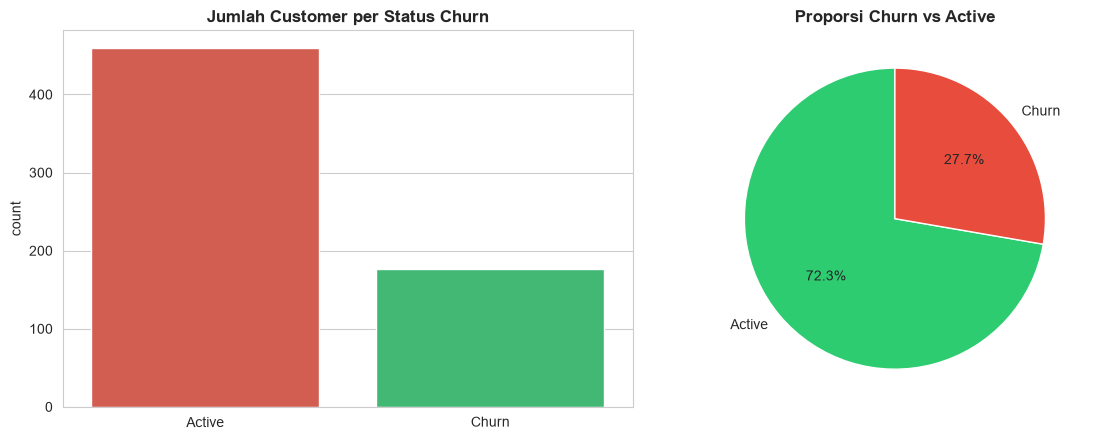


Insight: kalau rasio churn:active jauh dari 50:50, model klasifikasi nanti perlu
class_weight='balanced' atau resampling (SMOTE/undersampling), jangan andalkan
accuracy sebagai metrik utama - pakai recall/precision/F1/ROC-AUC per kelas churn.



In [3]:
churn_counts = cf['churn_flag'].value_counts().sort_index()
churn_pct = cf['churn_flag'].value_counts(normalize=True).sort_index() * 100

print("Distribusi churn_flag:")
for flag, cnt in churn_counts.items():
    label = 'Churn' if flag == 1 else 'Active'
    print(f"  {label} ({flag}): {cnt} customers ({churn_pct[flag]:.1f}%)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=cf, x='churn_label', hue='churn_label', palette=['#2ecc71', '#e74c3c'],
              order=['Active', 'Churn'], legend=False, ax=ax[0])
ax[0].set_title('Jumlah Customer per Status Churn')
ax[0].set_xlabel('')

ax[1].pie(churn_counts, labels=['Active', 'Churn'], autopct='%1.1f%%',
          colors=['#2ecc71', '#e74c3c'], startangle=90)
ax[1].set_title('Proporsi Churn vs Active')
plt.tight_layout()
plt.show()

print("""
Insight: kalau rasio churn:active jauh dari 50:50, model klasifikasi nanti perlu
class_weight='balanced' atau resampling (SMOTE/undersampling), jangan andalkan
accuracy sebagai metrik utama - pakai recall/precision/F1/ROC-AUC per kelas churn.
""")


### 2.2 Distribusi Fitur Numerik Kunci (Outlier & Skewness)

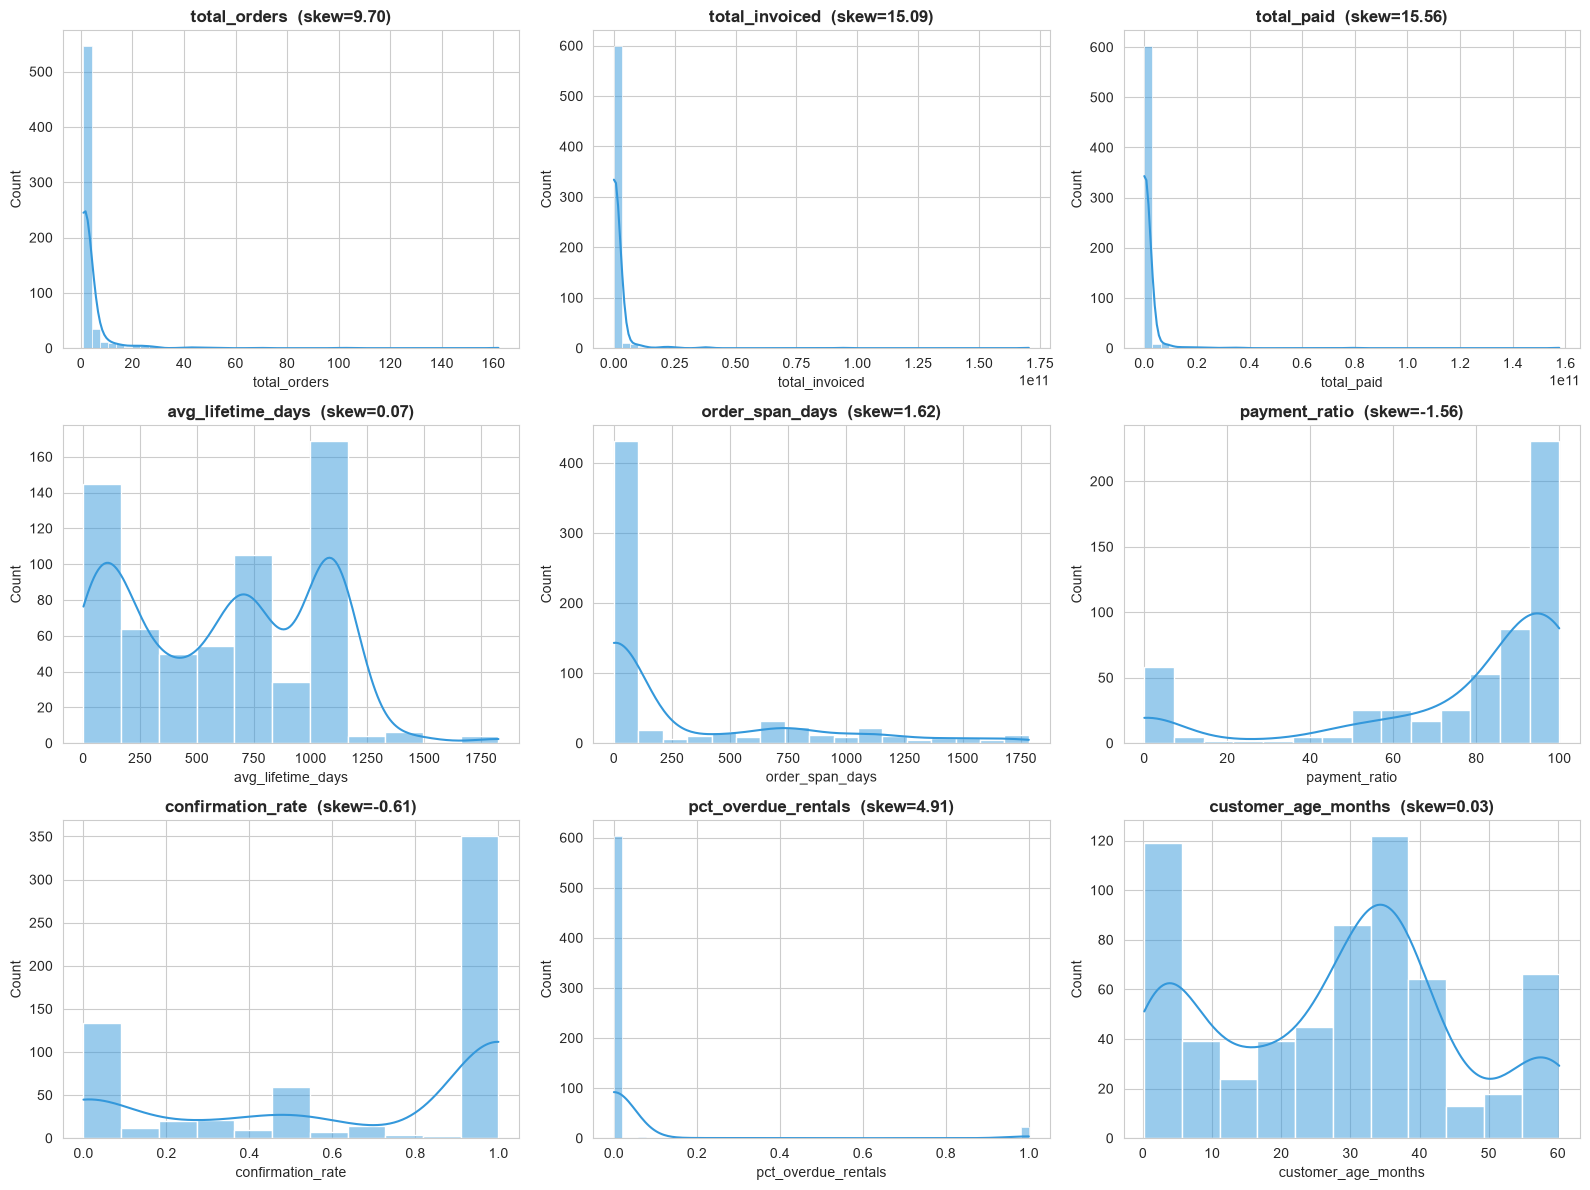

Ringkasan statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
total_orders,635.0,3.666142e+00,9.816713e+00,1.0,1.000000e+00,1.000000e+00,2.000000e+00,1.620000e+02
total_invoiced,635.0,1.384024e+09,8.482966e+09,0.0,3.313200e+07,1.478520e+08,3.994751e+08,1.704582e+11
total_paid,635.0,1.219841e+09,7.675760e+09,0.0,3.701250e+06,1.298700e+08,3.447150e+08,1.576655e+11
avg_lifetime_days,635.0,6.124670e+02,4.203484e+02,1.0,1.830000e+02,6.700000e+02,1.095000e+03,1.827000e+03
order_span_days,635.0,2.741213e+02,4.685729e+02,0.0,0.000000e+00,0.000000e+00,4.705000e+02,1.785000e+03
payment_ratio,542.0,7.625524e+01,3.144863e+01,0.0,6.751140e+01,9.006907e+01,9.733629e+01,1.000000e+02
confirmation_rate,635.0,6.570746e-01,4.164550e-01,0.0,2.500000e-01,1.000000e+00,1.000000e+00,1.000000e+00
pct_overdue_rentals,635.0,3.793312e-02,1.875974e-01,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
customer_age_months,635.0,2.788283e+01,1.754584e+01,0.2,1.140000e+01,3.010000e+01,3.850000e+01,6.020000e+01


In [4]:
key_numeric = ['total_orders', 'total_invoiced', 'total_paid', 'avg_lifetime_days',
                'order_span_days', 'payment_ratio', 'confirmation_rate',
                'pct_overdue_rentals', 'customer_age_months']
key_numeric = [c for c in key_numeric if c in cf.columns]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(key_numeric):
    sns.histplot(cf[col].dropna(), kde=True, ax=axes[i], color='#3498db')
    skew = cf[col].skew()
    axes[i].set_title(f'{col}  (skew={skew:.2f})')
for j in range(len(key_numeric), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

print("Ringkasan statistik deskriptif:")
cf[key_numeric].describe().T


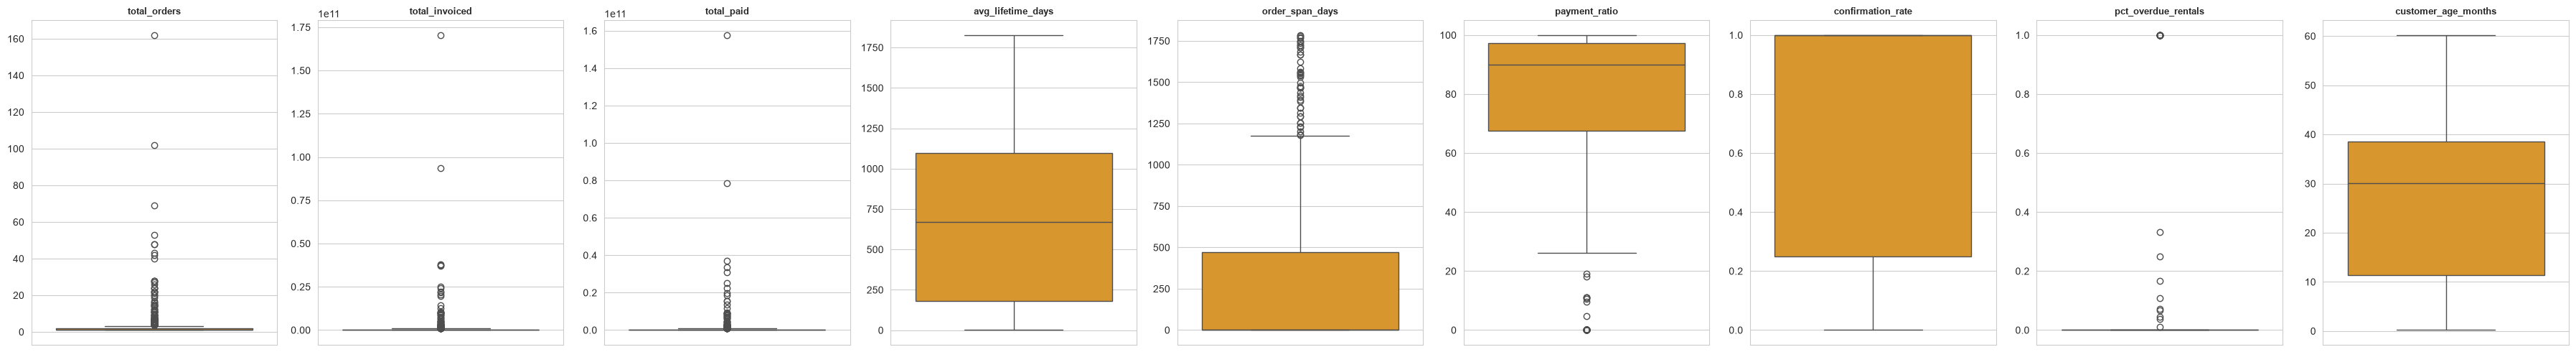


Insight: fitur dengan skew tinggi (mis. total_invoiced, total_paid) biasa punya
beberapa customer 'whale' bernilai jauh di atas rata-rata. Untuk model linear/KNN
ini sudah ditangani oleh StandardScaler di preprocessing, tapi kalau outlier-nya
ekstrem sekali, pertimbangkan log-transform atau cek apakah itu data entry error.



In [5]:
# Boxplot untuk cek outlier ekstrem
fig, axes = plt.subplots(1, len(key_numeric), figsize=(4*len(key_numeric), 5))
for i, col in enumerate(key_numeric):
    sns.boxplot(y=cf[col], ax=axes[i], color='#f39c12')
    axes[i].set_title(col, fontsize=9)
    axes[i].set_ylabel('')
plt.tight_layout()
plt.show()

print("""
Insight: fitur dengan skew tinggi (mis. total_invoiced, total_paid) biasa punya
beberapa customer 'whale' bernilai jauh di atas rata-rata. Untuk model linear/KNN
ini sudah ditangani oleh StandardScaler di preprocessing, tapi kalau outlier-nya
ekstrem sekali, pertimbangkan log-transform atau cek apakah itu data entry error.
""")


### 2.3 Fitur Kategorikal — Distribusi & Churn Rate

In [6]:
cat_cols = ['dominant_product_category', 'order_frequency_category',
            'order_span_quartile', 'purchase_pattern']
cat_cols = [c for c in cat_cols if c in cf.columns]

# Kalau file sudah di-one-hot-encode, rekonstruksi kategori dari kolom dummy
def reconstruct_categorical(df, prefix):
    dummy_cols = [c for c in df.columns if c.startswith(prefix + '_')]
    if not dummy_cols:
        return None
    sub = df[dummy_cols]
    cat = sub.idxmax(axis=1).str.replace(prefix + '_', '', regex=False)
    cat[sub.sum(axis=1) == 0] = 'Missing'
    return cat

for prefix in ['dominant_product_category', 'order_frequency_category',
               'order_span_quartile', 'purchase_pattern']:
    if prefix not in cf.columns:
        rec = reconstruct_categorical(cf, prefix)
        if rec is not None:
            cf[prefix] = rec
            cat_cols.append(prefix) if prefix not in cat_cols else None

cat_cols = [c for c in cat_cols if c in cf.columns]
print(f"Kolom kategorikal dianalisis: {cat_cols}")


Kolom kategorikal dianalisis: ['dominant_product_category', 'order_frequency_category', 'order_span_quartile', 'purchase_pattern']


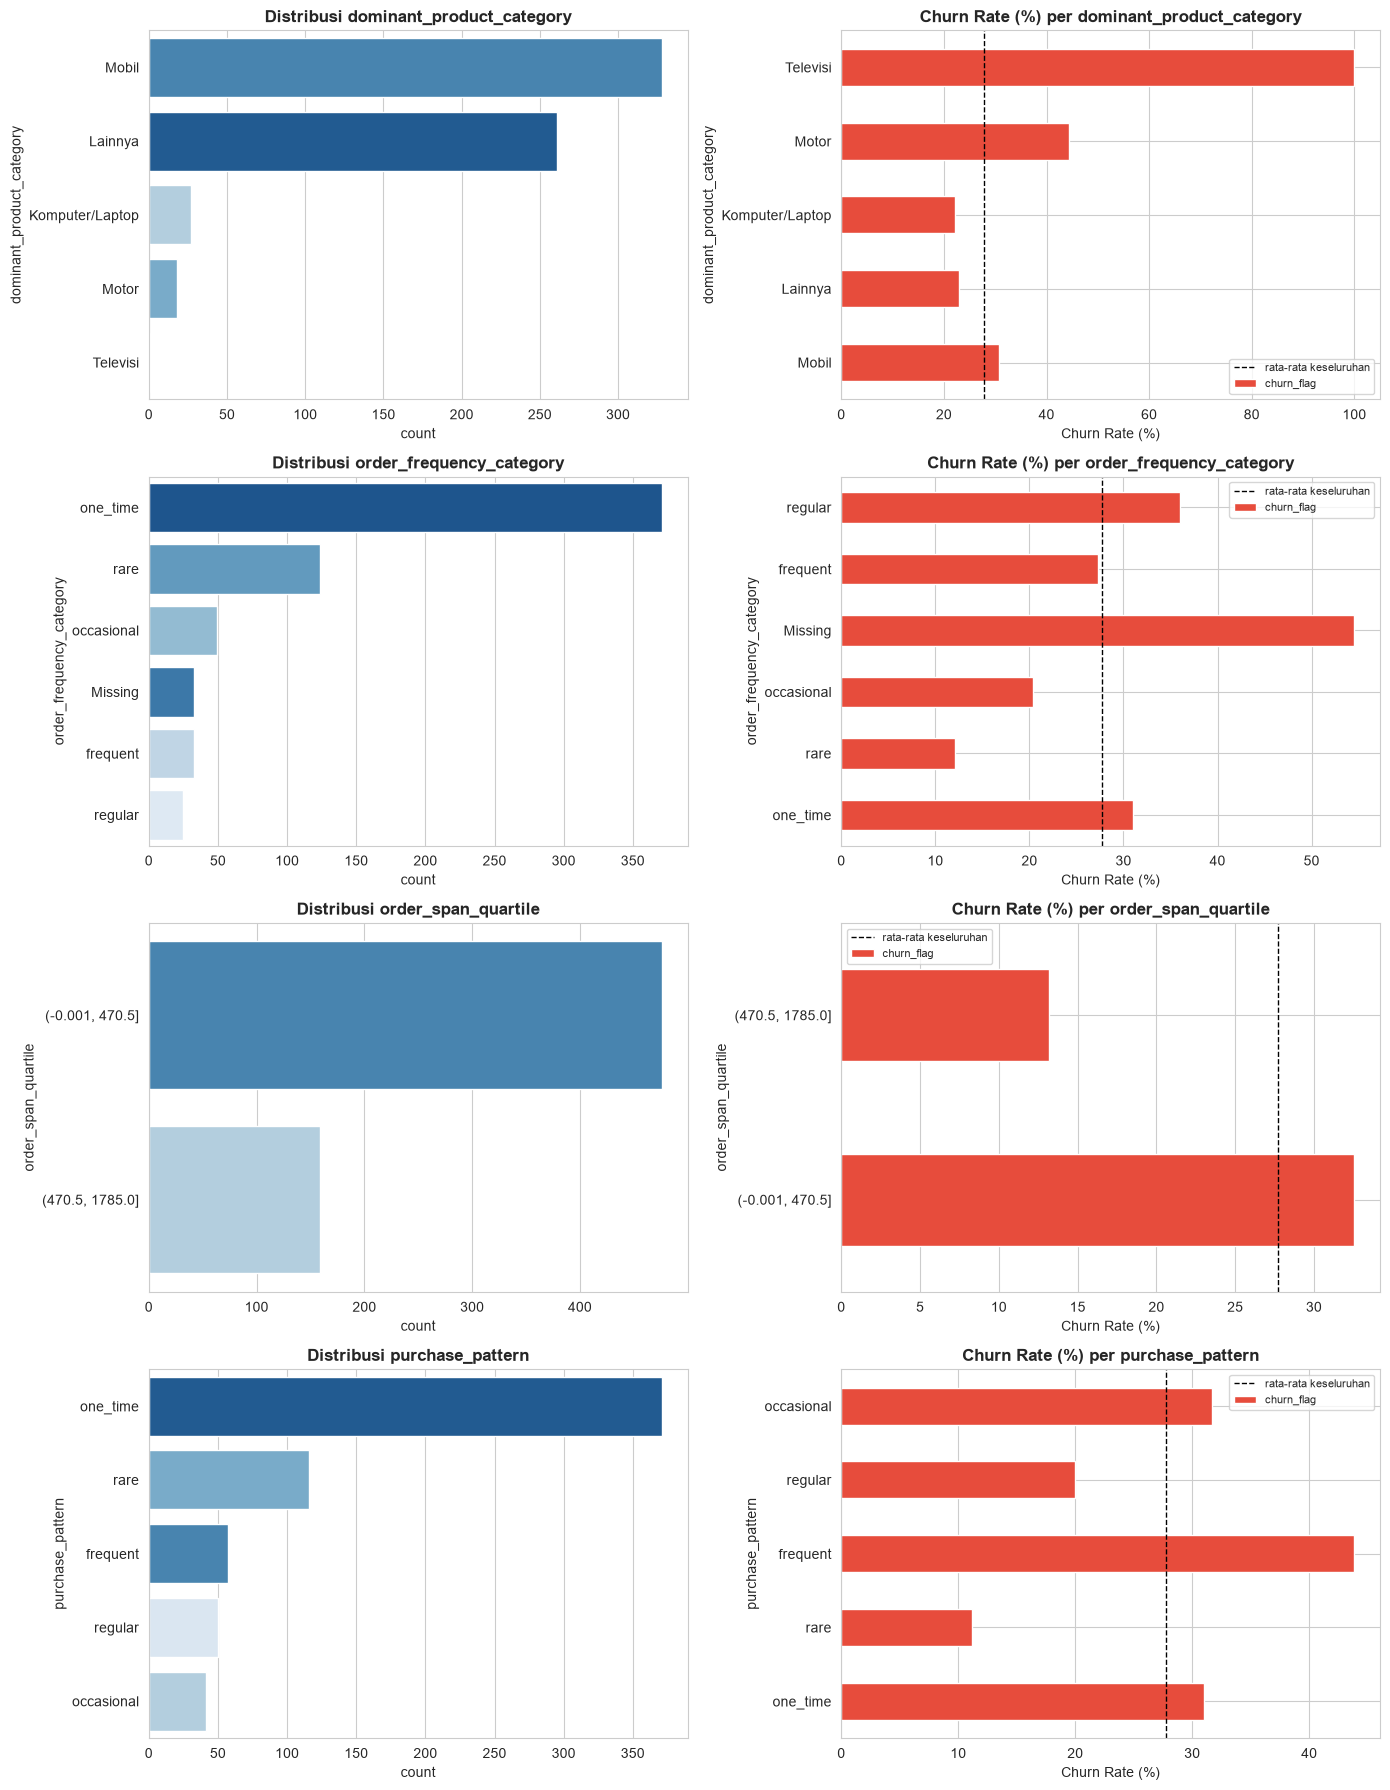

Tabel churn rate per kategori (urut dari tertinggi):

--- dominant_product_category ---
                           churn_rate_%  n_customers
dominant_product_category                           
Televisi                          100.0            1
Motor                              44.4           18
Mobil                              30.8          328
Lainnya                            23.0          261
Komputer/Laptop                    22.2           27

--- order_frequency_category ---
                          churn_rate_%  n_customers
order_frequency_category                           
Missing                           54.5           33
regular                           36.0           25
one_time                          31.0          371
frequent                          27.3           33
occasional                        20.4           49
rare                              12.1          124

--- order_span_quartile ---
                     churn_rate_%  n_customers
order_span_quar

In [7]:
fig, axes = plt.subplots(len(cat_cols), 2, figsize=(14, 4.5*len(cat_cols)))
if len(cat_cols) == 1:
    axes = axes.reshape(1, -1)

for i, col in enumerate(cat_cols):
    order = cf[col].value_counts().index

    sns.countplot(data=cf, y=col, order=order, hue=col, palette='Blues_r',
                  legend=False, ax=axes[i, 0])
    axes[i, 0].set_title(f'Distribusi {col}')

    churn_rate = cf.groupby(col)['churn_flag'].mean().reindex(order) * 100
    churn_rate.plot(kind='barh', ax=axes[i, 1], color='#e74c3c')
    axes[i, 1].set_title(f'Churn Rate (%) per {col}')
    axes[i, 1].set_xlabel('Churn Rate (%)')
    axes[i, 1].axvline(cf['churn_flag'].mean()*100, color='black', linestyle='--',
                        linewidth=1, label='rata-rata keseluruhan')
    axes[i, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Tabel churn rate per kategori (urut dari tertinggi):")
for col in cat_cols:
    tbl = cf.groupby(col)['churn_flag'].agg(['mean', 'count']).sort_values('mean', ascending=False)
    tbl['mean'] = (tbl['mean']*100).round(1)
    tbl.columns = ['churn_rate_%', 'n_customers']
    print(f"\n--- {col} ---")
    print(tbl)


### 2.4 Fitur Numerik vs Churn (Bivariate)

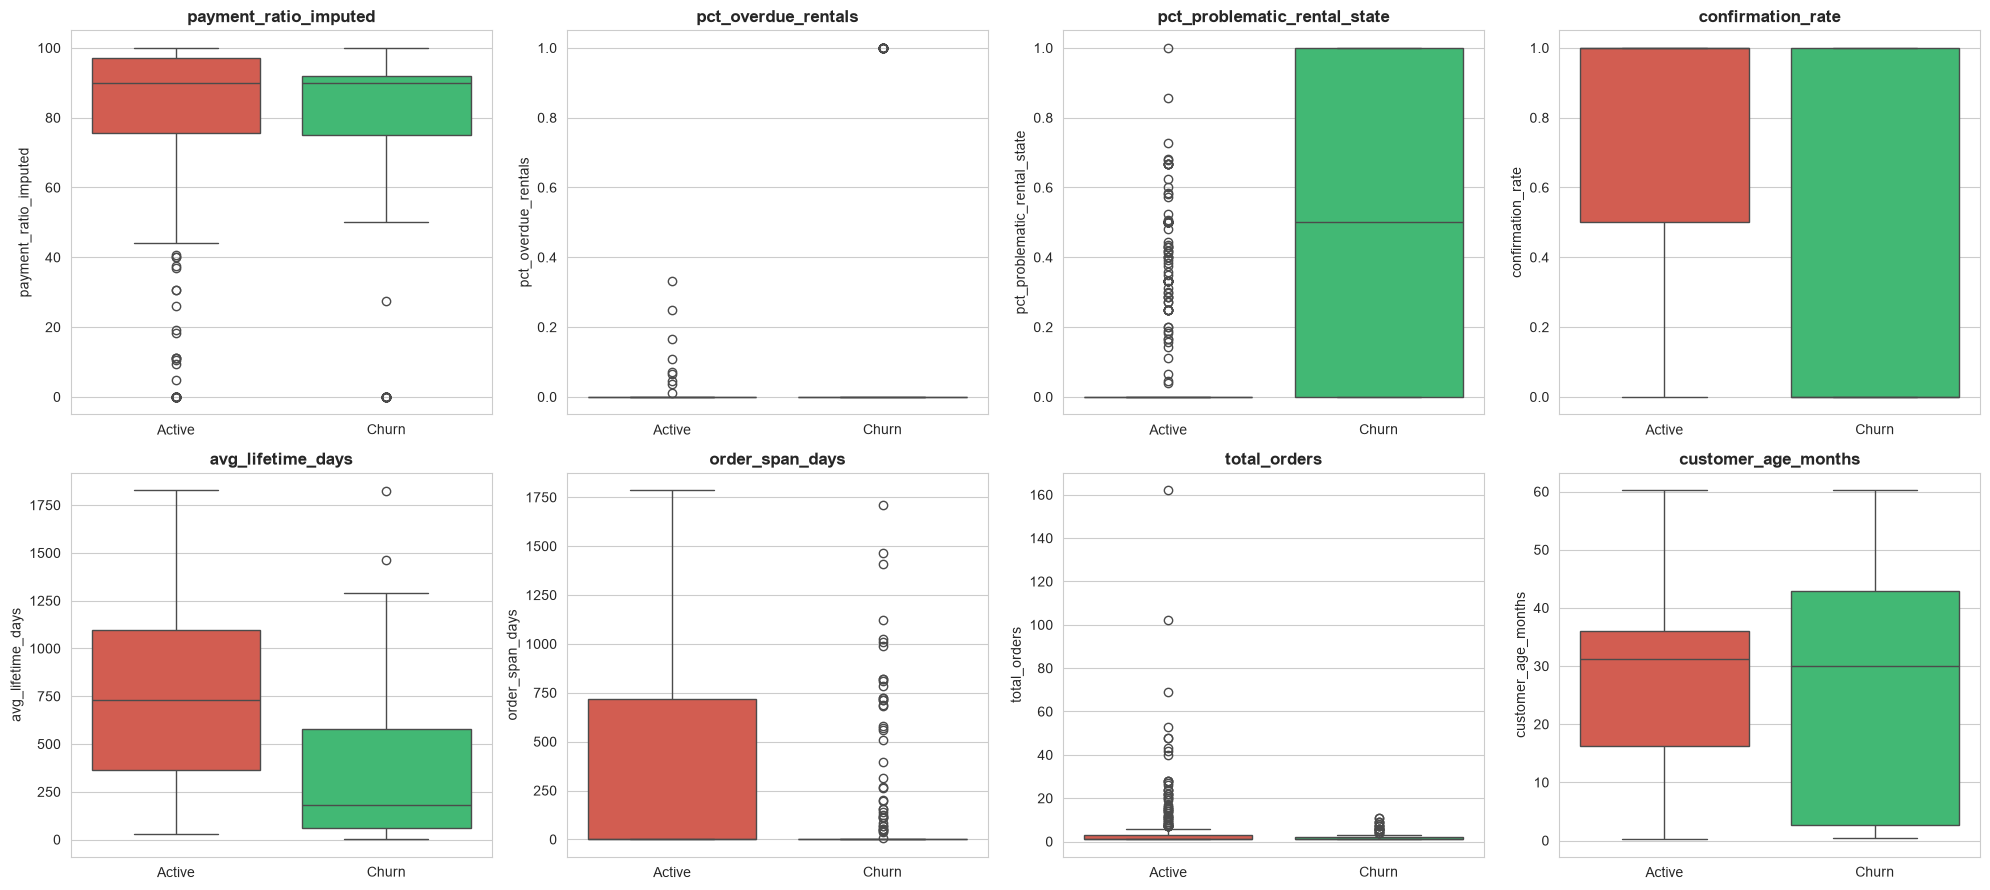

Rata-rata tiap fitur, Active vs Churn:


churn_label,Active,Churn
payment_ratio_imputed,79.62,74.79
pct_overdue_rentals,0.00,0.13
pct_problematic_rental_state,0.10,0.50
confirmation_rate,0.78,0.35
avg_lifetime_days,718.72,335.36
order_span_days,332.51,121.84
total_orders,4.31,2.00
customer_age_months,28.18,27.12


In [8]:
compare_cols = ['payment_ratio_imputed', 'pct_overdue_rentals', 'pct_problematic_rental_state',
                'confirmation_rate', 'avg_lifetime_days', 'order_span_days',
                'total_orders', 'customer_age_months']
compare_cols = [c for c in compare_cols if c in cf.columns]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
for i, col in enumerate(compare_cols):
    sns.boxplot(data=cf, x='churn_label', y=col, hue='churn_label',
                order=['Active', 'Churn'], palette=['#2ecc71', '#e74c3c'],
                legend=False, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
for j in range(len(compare_cols), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

print("Rata-rata tiap fitur, Active vs Churn:")
cf.groupby('churn_label')[compare_cols].mean().T.round(2)


In [9]:
# Uji beda rata-rata sederhana (Mann-Whitney U - tidak asumsi normal, cocok utk data skew)
from scipy.stats import mannwhitneyu

print("Signifikansi perbedaan Active vs Churn (Mann-Whitney U test, alpha=0.05):")
sig_results = []
for col in compare_cols:
    a = cf.loc[cf['churn_flag'] == 0, col].dropna()
    b = cf.loc[cf['churn_flag'] == 1, col].dropna()
    if len(a) > 0 and len(b) > 0:
        stat, p = mannwhitneyu(a, b, alternative='two-sided')
        sig_results.append({'feature': col, 'p_value': round(p, 4), 'signifikan': p < 0.05})

sig_df = pd.DataFrame(sig_results).sort_values('p_value')
print(sig_df.to_string(index=False))

print("""
Insight: fitur dengan p_value < 0.05 punya perbedaan distribusi yang signifikan
secara statistik antara customer Active vs Churn - kandidat kuat sebagai fitur
prediktif. Fitur dengan p_value tinggi kemungkinan tidak terlalu berguna sendirian
(meski masih bisa berguna dalam kombinasi/interaksi dengan fitur lain).
""")


Signifikansi perbedaan Active vs Churn (Mann-Whitney U test, alpha=0.05):
                     feature  p_value  signifikan
         pct_overdue_rentals   0.0000        True
pct_problematic_rental_state   0.0000        True
           confirmation_rate   0.0000        True
           avg_lifetime_days   0.0000        True
             order_span_days   0.0000        True
                total_orders   0.0121        True
       payment_ratio_imputed   0.2066       False
         customer_age_months   0.3649       False

Insight: fitur dengan p_value < 0.05 punya perbedaan distribusi yang signifikan
secara statistik antara customer Active vs Churn - kandidat kuat sebagai fitur
prediktif. Fitur dengan p_value tinggi kemungkinan tidak terlalu berguna sendirian
(meski masih bisa berguna dalam kombinasi/interaksi dengan fitur lain).



### 2.5 Korelasi Fitur ke Target (dari `feature_selection_recommendation.csv`)

Top 15 fitur dengan korelasi absolut tertinggi ke churn_flag:
                          feature  abs_corr_with_churn  recommend_drop_low_corr
     pct_problematic_rental_state             0.535432                    False
       pct_sms_on_going_delivered             0.498602                    False
      pct_status_confirmed_rental             0.459469                    False
                confirmation_rate             0.459469                    False
         pct_status_closed_rental             0.459469                    False
                 has_payment_data             0.410219                    False
                avg_lifetime_days             0.408534                    False
                  pct_sms_unknown             0.397403                    False
              pct_overdue_rentals             0.306389                    False
    pct_sms_expired_rent_on_going             0.306389                    False
            pct_sms_closed_rental             0.241885    

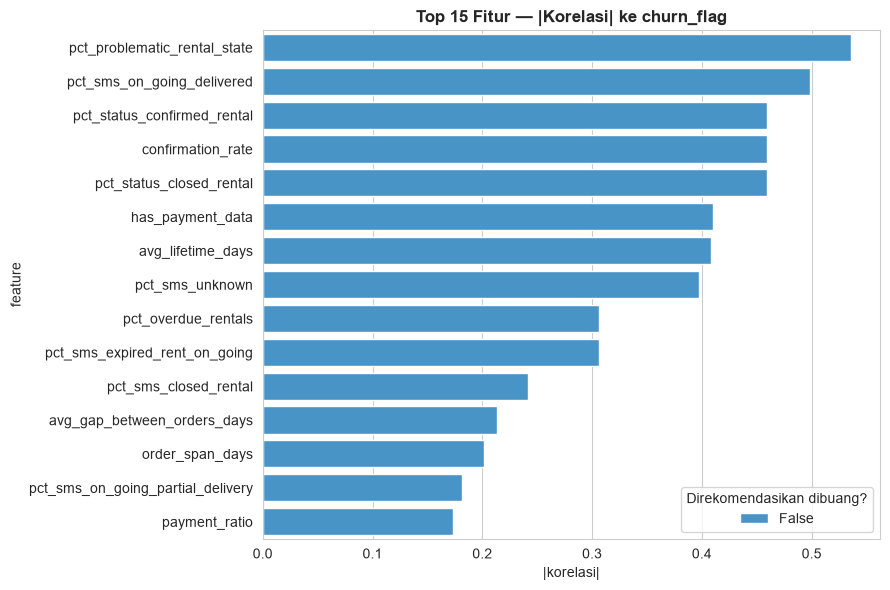


10 dari 42 fitur punya korelasi rendah (<0.05) ke target dan menjadi kandidat dibuang saat feature selection.


In [10]:
print("Top 15 fitur dengan korelasi absolut tertinggi ke churn_flag:")
display_top = feat_sel.sort_values('abs_corr_with_churn', ascending=False).head(15)
print(display_top.to_string(index=False))

plt.figure(figsize=(9, 6))
top15 = feat_sel.sort_values('abs_corr_with_churn', ascending=False).head(15)
sns.barplot(data=top15, x='abs_corr_with_churn', y='feature', hue='recommend_drop_low_corr',
            dodge=False, palette={True: '#95a5a6', False: '#3498db'})
plt.title('Top 15 Fitur — |Korelasi| ke churn_flag')
plt.xlabel('|korelasi|')
plt.legend(title='Direkomendasikan dibuang?', loc='lower right')
plt.tight_layout()
plt.show()

n_low_corr = feat_sel['recommend_drop_low_corr'].sum()
print(f"\n{n_low_corr} dari {len(feat_sel)} fitur punya korelasi rendah (<0.05) ke target "
      f"dan menjadi kandidat dibuang saat feature selection.")


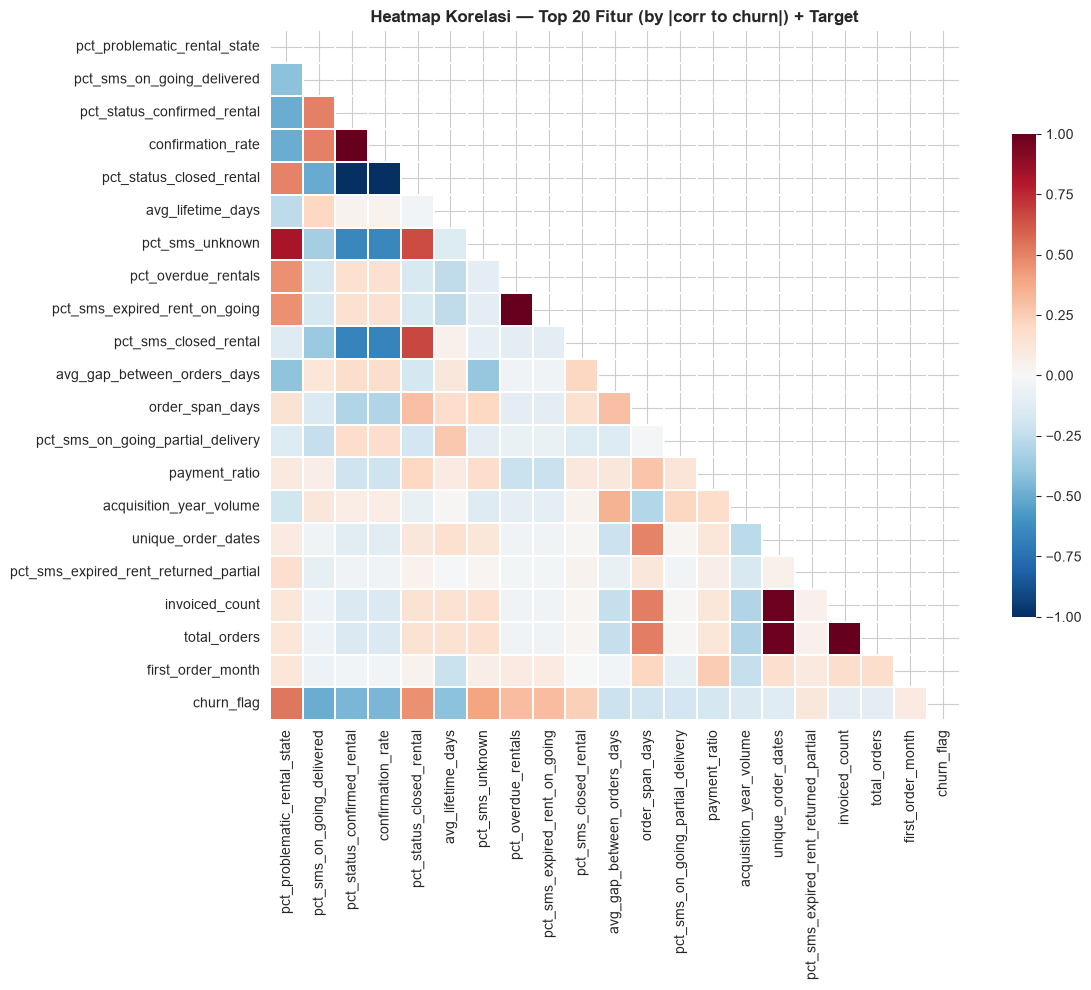


Insight: cari pasangan fitur dengan warna sangat pekat (|corr| > 0.9 di luar diagonal)
- ini pasangan redundan (sudah terdeteksi juga di feature_selection_recommendation.csv
saat preprocessing, mis. total_paid vs total_invoiced). Untuk model linear, pertimbangkan
buang salah satu supaya tidak multikolinearitas; untuk tree-based biasanya tidak masalah.



In [11]:
# Heatmap korelasi antar fitur numerik utama (cek multikolinearitas / redundansi)
numeric_cols_corr = cf.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols_corr = [c for c in numeric_cols_corr if c != 'churn_flag']
# batasi ke fitur dengan variance tidak nol dan bukan dummy 0/1 supaya heatmap terbaca
non_binary = [c for c in numeric_cols_corr if cf[c].nunique() > 2]
top_by_corr = feat_sel.sort_values('abs_corr_with_churn', ascending=False)['feature'].tolist()
heatmap_cols = [c for c in top_by_corr if c in non_binary][:20]

plt.figure(figsize=(13, 10))
corr_matrix = cf[heatmap_cols + ['churn_flag']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='RdBu_r', center=0, annot=False,
            square=True, linewidths=0.3, cbar_kws={'shrink': 0.7})
plt.title('Heatmap Korelasi — Top 20 Fitur (by |corr to churn|) + Target')
plt.tight_layout()
plt.show()

print("""
Insight: cari pasangan fitur dengan warna sangat pekat (|corr| > 0.9 di luar diagonal)
- ini pasangan redundan (sudah terdeteksi juga di feature_selection_recommendation.csv
saat preprocessing, mis. total_paid vs total_invoiced). Untuk model linear, pertimbangkan
buang salah satu supaya tidak multikolinearitas; untuk tree-based biasanya tidak masalah.
""")


### 2.6 Missing Value Check (Pasca-Preprocessing)

                             missing_count  missing_pct
order_frequency_per_month              404         63.6
avg_gap_between_orders_days            371         58.4
payment_ratio                           93         14.6


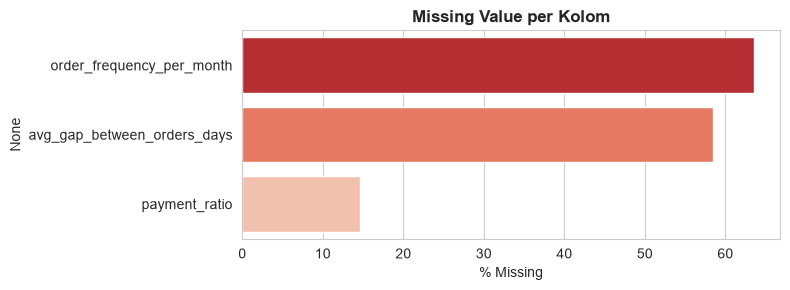


Insight: berdasarkan Step 14 preprocessing, NaN yang tersisa di sini sifatnya
structural (customer one-time tidak punya order_frequency_per_month/avg_gap, dst)
dan sudah punya flag pendamping (is_one_time_customer, has_payment_data).
Kalau ada kolom missing yang TIDAK terduga di sini, cek ulang step preprocessing terkait.



In [12]:
missing = cf.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) == 0:
    print("✓ Tidak ada missing value tersisa di customer_churn_features.csv")
else:
    missing_pct = (missing / len(cf) * 100).round(1)
    missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
    print(missing_summary)

    plt.figure(figsize=(8, max(3, 0.35*len(missing))))
    sns.barplot(x=missing_pct.values, y=missing_pct.index, hue=missing_pct.index,
                palette='Reds_r', legend=False)
    plt.xlabel('% Missing')
    plt.title('Missing Value per Kolom')
    plt.tight_layout()
    plt.show()

print("""
Insight: berdasarkan Step 14 preprocessing, NaN yang tersisa di sini sifatnya
structural (customer one-time tidak punya order_frequency_per_month/avg_gap, dst)
dan sudah punya flag pendamping (is_one_time_customer, has_payment_data).
Kalau ada kolom missing yang TIDAK terduga di sini, cek ulang step preprocessing terkait.
""")


## 3. EDA — `orders_churn_detailed.csv` (Order-Level)

### 3.1 Tren Order & Seasonality

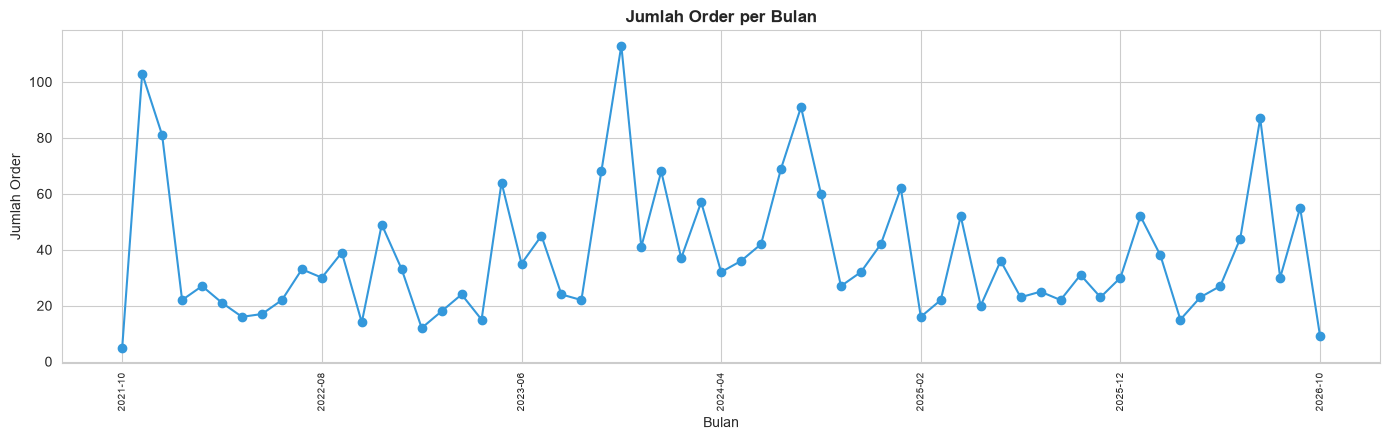

Jumlah order per tahun:
order_year
2021    189
2022    323
2023    481
2024    593
2025    362
2026    380
dtype: int64

Insight: perhatikan apakah ada penurunan tajam order di periode tertentu -
ini bisa jadi konteks penting kenapa banyak customer churn di sekitar periode
tersebut (faktor eksternal bisnis, bukan cuma perilaku individual customer).



In [13]:
orders['order_year'] = orders['Order Date'].dt.year
orders['order_month'] = orders['Order Date'].dt.to_period('M').astype(str)

monthly = orders.groupby('order_month').size()

fig, ax = plt.subplots(figsize=(14, 4.5))
monthly.plot(kind='line', marker='o', ax=ax, color='#3498db')
ax.set_title('Jumlah Order per Bulan')
ax.set_xlabel('Bulan')
ax.set_ylabel('Jumlah Order')
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

print("Jumlah order per tahun:")
print(orders.groupby('order_year').size())

print("""
Insight: perhatikan apakah ada penurunan tajam order di periode tertentu -
ini bisa jadi konteks penting kenapa banyak customer churn di sekitar periode
tersebut (faktor eksternal bisnis, bukan cuma perilaku individual customer).
""")


### 3.2 Distribusi SMS Rental State & Order Status

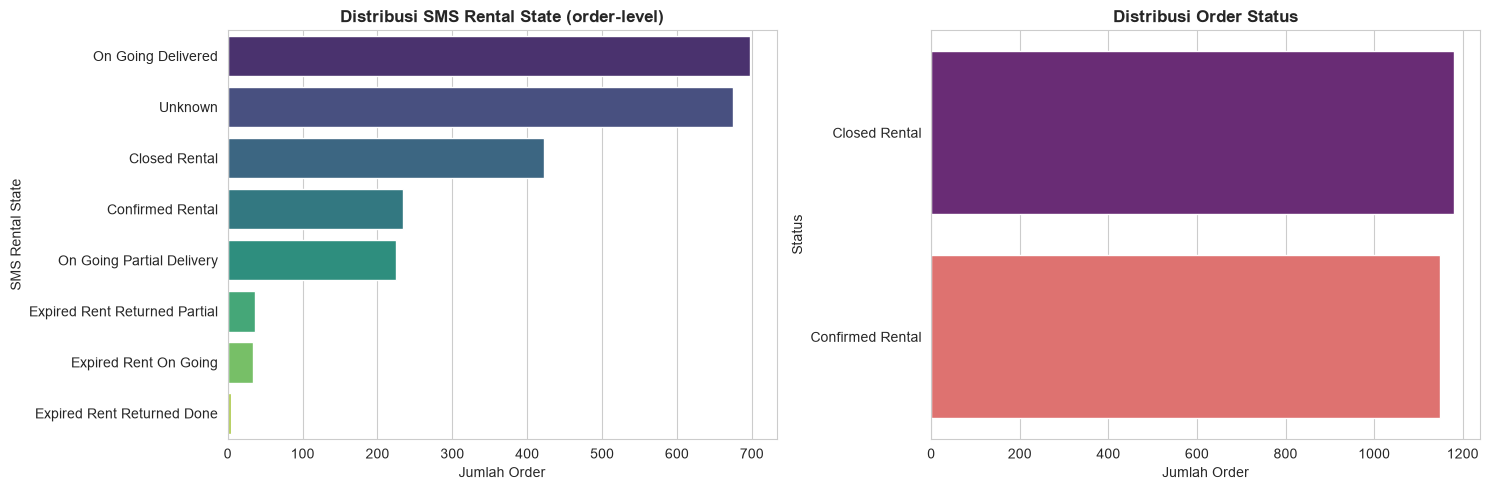

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sms_counts = orders['SMS Rental State'].value_counts()
sns.barplot(x=sms_counts.values, y=sms_counts.index, hue=sms_counts.index,
            palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Distribusi SMS Rental State (order-level)')
axes[0].set_xlabel('Jumlah Order')

status_counts = orders['Status'].value_counts()
sns.barplot(x=status_counts.values, y=status_counts.index, hue=status_counts.index,
            palette='magma', legend=False, ax=axes[1])
axes[1].set_title('Distribusi Order Status')
axes[1].set_xlabel('Jumlah Order')

plt.tight_layout()
plt.show()


### 3.3 Rate Overdue per Kategori Produk

                  overdue_rate_%  n_orders
product_category                          
Mobil                        2.0      1270
Lainnya                      1.2       503
Komputer/Laptop              0.5       428
Motor                        0.0       125
Televisi                     0.0         2


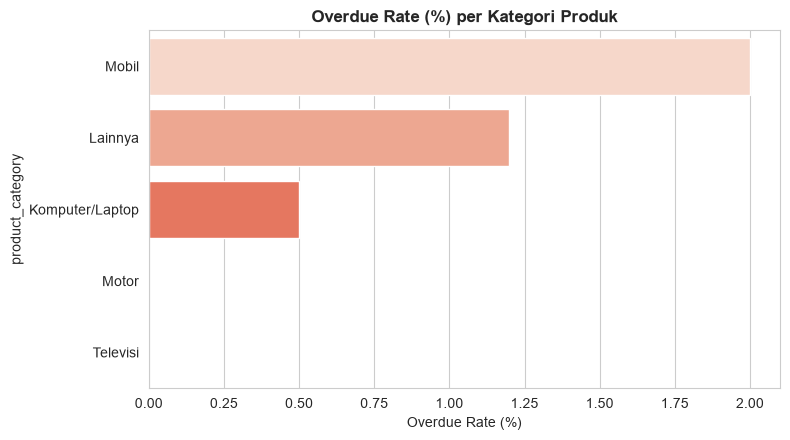


Insight: kategori produk dengan overdue rate tinggi adalah kandidat akar masalah
operasional (bukan cuma gejala) yang bisa mendorong churn - worth didiskusikan
dengan tim operasional/sales, bukan cuma dijadikan fitur model.



In [15]:
if 'product_category' in orders.columns and 'is_overdue' in orders.columns:
    overdue_by_cat = orders.groupby('product_category')['is_overdue'].agg(['mean', 'count'])
    overdue_by_cat['mean'] = (overdue_by_cat['mean'] * 100).round(1)
    overdue_by_cat.columns = ['overdue_rate_%', 'n_orders']
    overdue_by_cat = overdue_by_cat.sort_values('overdue_rate_%', ascending=False)
    print(overdue_by_cat)

    plt.figure(figsize=(8, 4.5))
    sns.barplot(x=overdue_by_cat['overdue_rate_%'], y=overdue_by_cat.index,
                hue=overdue_by_cat.index, palette='Reds', legend=False)
    plt.title('Overdue Rate (%) per Kategori Produk')
    plt.xlabel('Overdue Rate (%)')
    plt.tight_layout()
    plt.show()

    print("""
Insight: kategori produk dengan overdue rate tinggi adalah kandidat akar masalah
operasional (bukan cuma gejala) yang bisa mendorong churn - worth didiskusikan
dengan tim operasional/sales, bukan cuma dijadikan fitur model.
""")
else:
    print("Kolom product_category / is_overdue tidak ditemukan di orders_churn_detailed.csv")


## 4. EDA — `draft_quotations_segment.csv` (Segmen Lead/Orphan)

Total customer dengan draft quotation: 14
Orphan customers (draft only, tidak pernah confirmed): 1 (7.1%)

Ringkasan draft_project_value: Orphan vs Bukan Orphan
                      mean           sum  count
is_orphan                                      
Bukan Orphan  7.195830e+09  9.354579e+10     13
Orphan        1.768000e+07  1.768000e+07      1


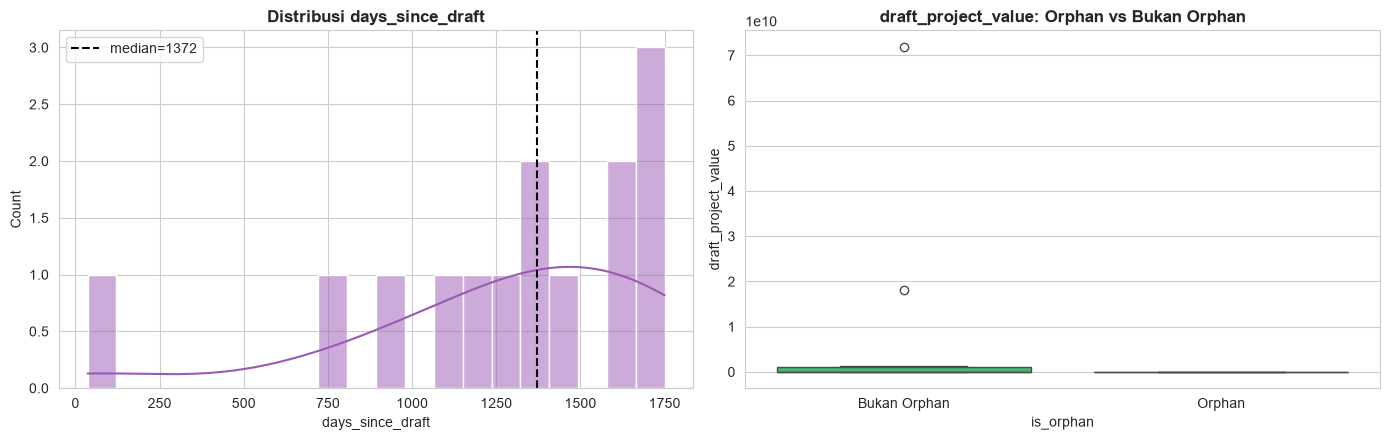


Insight: orphan customer dengan draft_project_value besar dan days_since_draft
kecil (masih baru) adalah lead paling potensial untuk di-follow-up sales -
segmen ini di luar scope model churn tapi bernilai bisnis langsung.



In [16]:
print(f"Total customer dengan draft quotation: {len(draft)}")
print(f"Orphan customers (draft only, tidak pernah confirmed): {draft['is_orphan'].sum()} "
      f"({100*draft['is_orphan'].mean():.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(draft['days_since_draft'], bins=20, kde=True, ax=axes[0], color='#9b59b6')
axes[0].set_title('Distribusi days_since_draft')
axes[0].axvline(draft['days_since_draft'].median(), color='black', linestyle='--',
                 label=f"median={draft['days_since_draft'].median():.0f}")
axes[0].legend()

orphan_summary = draft.groupby('is_orphan')['draft_project_value'].agg(['mean', 'sum', 'count'])
orphan_summary = orphan_summary.rename(index={False: 'Bukan Orphan', True: 'Orphan'})
print("\nRingkasan draft_project_value: Orphan vs Bukan Orphan")
print(orphan_summary)

if draft['is_orphan'].nunique() > 1:
    sns.boxplot(data=draft, x='is_orphan', y='draft_project_value', hue='is_orphan',
                palette=['#2ecc71', '#e67e22'], legend=False, ax=axes[1])
    axes[1].set_xticklabels(['Bukan Orphan', 'Orphan'])
    axes[1].set_title('draft_project_value: Orphan vs Bukan Orphan')
else:
    axes[1].text(0.5, 0.5, 'Hanya 1 kategori is_orphan pada data ini',
                  ha='center', va='center', fontsize=10)
    axes[1].set_title('draft_project_value: Orphan vs Bukan Orphan')
    axes[1].axis('off')
plt.tight_layout()
plt.show()

print("""
Insight: orphan customer dengan draft_project_value besar dan days_since_draft
kecil (masih baru) adalah lead paling potensial untuk di-follow-up sales -
segmen ini di luar scope model churn tapi bernilai bisnis langsung.
""")


## 5. Sanity Check — Train vs Test Split

Pastikan hasil `train_test_split` (stratified) benar-benar representatif: distribusi churn
dan fitur kunci antara train dan test tidak jomplang.

Churn rate train: 27.8%
Churn rate test : 27.6%


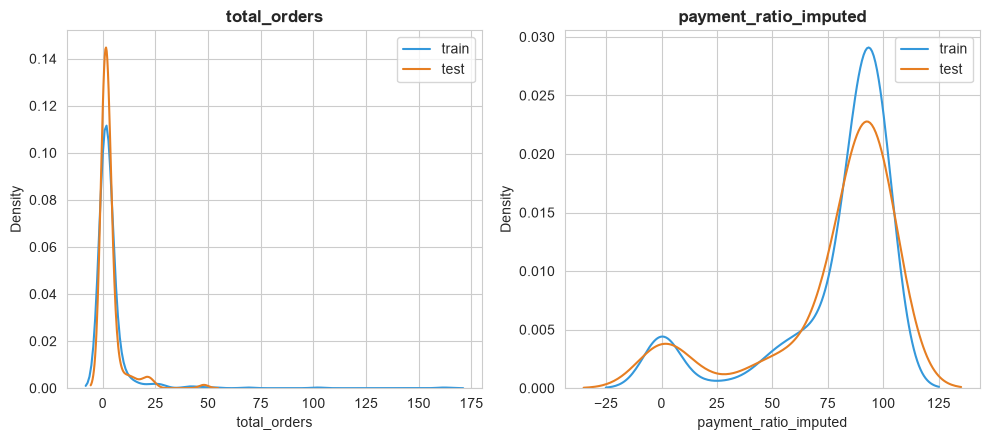


Insight: distribusi train vs test yang berhimpit (kurva saling tumpang tindih)
menandakan split representatif. Kalau ada kurva yang jauh berbeda, waspada
sample size test terlalu kecil (data ini cuma ratusan customer) - hasil evaluasi
model di test set perlu dibaca dengan interval kepercayaan yang lebar,
pertimbangkan cross-validation di train set untuk evaluasi yang lebih stabil.



In [17]:
print(f"Churn rate train: {train_unscaled['churn_flag'].mean()*100:.1f}%")
print(f"Churn rate test : {test_unscaled['churn_flag'].mean()*100:.1f}%")

check_cols = [c for c in ['total_orders', 'payment_ratio_imputed', 'order_span_days',
                           'pct_overdue_rentals'] if c in train_unscaled.columns]

fig, axes = plt.subplots(1, len(check_cols), figsize=(5*len(check_cols), 4.5))
if len(check_cols) == 1:
    axes = [axes]
for i, col in enumerate(check_cols):
    sns.kdeplot(train_unscaled[col].dropna(), label='train', ax=axes[i], color='#3498db')
    sns.kdeplot(test_unscaled[col].dropna(), label='test', ax=axes[i], color='#e67e22')
    axes[i].set_title(col)
    axes[i].legend()
plt.tight_layout()
plt.show()

print("""
Insight: distribusi train vs test yang berhimpit (kurva saling tumpang tindih)
menandakan split representatif. Kalau ada kurva yang jauh berbeda, waspada
sample size test terlalu kecil (data ini cuma ratusan customer) - hasil evaluasi
model di test set perlu dibaca dengan interval kepercayaan yang lebar,
pertimbangkan cross-validation di train set untuk evaluasi yang lebih stabil.
""")


## 6. Ringkasan Insight & Rekomendasi untuk Modeling

In [18]:
n_customers = len(cf)
churn_rate_overall = cf['churn_flag'].mean() * 100
top5_features = feat_sel.sort_values('abs_corr_with_churn', ascending=False).head(5)['feature'].tolist()
n_drop_candidates = feat_sel['recommend_drop_low_corr'].sum()

print("=" * 80)
print("RINGKASAN EDA")
print("=" * 80)
print(f"""
1. TARGET
   - Total customer: {n_customers}, churn rate: {churn_rate_overall:.1f}%
   - {'Imbalance ringan' if 40 <= churn_rate_overall <= 60 else 'Imbalance perlu ditangani (class_weight/resampling)'}

2. FITUR PALING PREDIKTIF (korelasi tertinggi ke churn_flag)
   {top5_features}

3. KUALITAS DATA
   - Missing value yang tersisa bersifat structural & sudah di-flag, aman dipakai
   - {n_drop_candidates} fitur berkorelasi rendah (<0.05) - kandidat dibuang atau
     digabung/direkayasa ulang jadi fitur interaksi

4. TEMUAN BISNIS DI LUAR SCOPE MODEL
   - Cek tren order per bulan untuk periode penurunan tajam (dampak eksternal)
   - Kategori produk dengan overdue rate tinggi - akar masalah operasional
   - Orphan customer bernilai tinggi - segmen lead-conversion terpisah dari model churn

5. REKOMENDASI LANGKAH MODELING
   - Split train/test sudah representatif (lihat Section 5) - lanjut ke modeling
   - Mulai dengan model tree-based (train_unscaled.csv) sebagai baseline karena
     tahan NaN & tidak sensitif skala
   - Bandingkan dengan model linear (train_scaled.csv) untuk cek apakah hubungan
     fitur-target cenderung linear atau butuh model non-linear
   - Prioritaskan fitur dari feature_selection_recommendation.csv dengan korelasi
     tinggi, tapi jangan buang fitur kategorikal biner hasil one-hot hanya karena
     korelasi individual rendah - random forest bisa menangkap interaksinya
   - Gunakan metrik evaluasi: ROC-AUC, precision/recall/F1 untuk kelas churn
     (bukan accuracy saja), terutama kalau imbalance terkonfirmasi di atas
""")


RINGKASAN EDA

1. TARGET
   - Total customer: 635, churn rate: 27.7%
   - Imbalance perlu ditangani (class_weight/resampling)

2. FITUR PALING PREDIKTIF (korelasi tertinggi ke churn_flag)
   ['pct_problematic_rental_state', 'pct_sms_on_going_delivered', 'pct_status_confirmed_rental', 'confirmation_rate', 'pct_status_closed_rental']

3. KUALITAS DATA
   - Missing value yang tersisa bersifat structural & sudah di-flag, aman dipakai
   - 10 fitur berkorelasi rendah (<0.05) - kandidat dibuang atau
     digabung/direkayasa ulang jadi fitur interaksi

4. TEMUAN BISNIS DI LUAR SCOPE MODEL
   - Cek tren order per bulan untuk periode penurunan tajam (dampak eksternal)
   - Kategori produk dengan overdue rate tinggi - akar masalah operasional
   - Orphan customer bernilai tinggi - segmen lead-conversion terpisah dari model churn

5. REKOMENDASI LANGKAH MODELING
   - Split train/test sudah representatif (lihat Section 5) - lanjut ke modeling
   - Mulai dengan model tree-based (train_unscaled.csv)